In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "src" / "common.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.common import PERIODS

PERIOD = "1990-2004"
START, END = PERIODS[PERIOD]
RESULTS = ROOT / "periods" / PERIOD / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

## Data

In [2]:
raw = pd.read_csv(ROOT / "data" / "raw" / "2026-09-MD.csv")
tcodes = pd.to_numeric(raw.iloc[0, 1:]).astype(int)

raw_panel = raw.iloc[1:].copy()
raw_panel.index = pd.to_datetime(raw_panel["sasdate"], format="%m/%d/%Y")
raw_panel = raw_panel.drop(columns="sasdate").apply(pd.to_numeric, errors="coerce")

def transform(s, c):
    with np.errstate(all="ignore"):
        if c == 1: return s
        if c == 2: return s.diff()
        if c == 3: return s.diff().diff()
        if c == 4: return np.log(s)
        if c == 5: return np.log(s).diff()
        if c == 6: return np.log(s).diff().diff()
        if c == 7: return (s / s.shift(1) - 1).diff()

# no outlier removal; first two rows are lost to differencing
tf_full = pd.DataFrame({v: transform(raw_panel[v], tcodes[v]) for v in raw_panel.columns}).iloc[2:]
tf_period = tf_full.loc[START:END]
print(tf_period.shape)   # (180, 126)

(180, 126)


In [3]:
audit = pd.DataFrame({
    "n_missing": tf_period.isna().sum(),
    "pct_missing": (100 * tf_period.isna().mean()).round(1),
    "first_obs": tf_period.apply(lambda s: s.first_valid_index()).dt.strftime("%Y-%m"),
    "last_obs": tf_period.apply(lambda s: s.last_valid_index()).dt.strftime("%Y-%m"),
})
print(audit[audit.n_missing > 0].sort_values("n_missing", ascending=False))
print("complete series:", int((audit.n_missing == 0).sum()), "of", tf_period.shape[1])

        n_missing  pct_missing first_obs last_obs
ACOGNO         26         14.4   1992-03  2004-12
complete series: 125 of 126


In [4]:
med = tf_period.median()
iqr = tf_period.quantile(0.75) - tf_period.quantile(0.25)
ratio = (tf_period - med).abs() / iqr.where(iqr > 0)
hits = ratio.stack()
flagged = hits[hits > 10].reset_index()
flagged.columns = ["date", "series", "x_over_IQR"]
flagged["date"] = flagged["date"].dt.strftime("%Y-%m")
print(flagged.round(2).to_string(index=False))

   date   series  x_over_IQR
2001-10     M1SL       12.96
2001-10 TOTRESNS       11.45


In [5]:
stats = pd.DataFrame({
    "tcode": tcodes, "n": tf_period.count(), "mean": tf_period.mean(),
    "sd": tf_period.std(), "skew": tf_period.skew(), "kurt": tf_period.kurt() + 3,
})
stats.round(4).to_csv(RESULTS / "descriptive_stats.csv")
print(stats.sort_values("kurt", ascending=False).head(6).round(3))

corr = tf_period.corr()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
top = upper.reindex(upper.abs().sort_values(ascending=False).index)
top.head(50).round(3).to_csv(RESULTS / "top_correlated_pairs.csv")
print(top.head(8).round(3))
print("share of pairs with |corr| > 0.5:", round(float((upper.abs() > 0.5).mean()), 3))

                 tcode    n   mean     sd   skew    kurt
TOTRESNS             6  180 -0.000  0.069 -3.415  44.186
M1SL                 6  180 -0.000  0.009 -3.351  42.843
NONBORRES            7  180 -0.000  0.064 -2.615  37.141
DSERRG3M086SBEA      6  180 -0.000  0.002  2.043  25.255
W875RX1              5  180  0.002  0.007  1.139  21.311
RPI                  5  180  0.003  0.006  1.514  21.084
TOTRESNS    NONBORRES     0.994
AAAFFM      BAAFFM        0.991
PERMIT      PERMITS       0.990
RPI         W875RX1       0.990
WPSFD49207  WPSFD49502    0.988
IPFPNSS     IPFINAL       0.980
T5YFFM      T10YFFM       0.980
HOUST       HOUSTS        0.977
dtype: float64
share of pairs with |corr| > 0.5: 0.021


In [6]:
# ACOGNO starts in 1992-03: 26 of 180 months (14.4%) are structurally missing
panel_no_acogno = tf_period.drop(columns="ACOGNO")
print(panel_no_acogno.shape, "| NA left:", int(panel_no_acogno.isna().sum().sum()))   # (180, 125) | NA left: 0

(180, 125) | NA left: 0


## Method

In [8]:
# Exploratory only: standardised with the full 1990-2004 sample (not used for forecasting)
Z_all = (panel_no_acogno - panel_no_acogno.mean()) / panel_no_acogno.std(ddof=0)
T, N = Z_all.shape

eigval, eigvec = np.linalg.eigh(np.cov(Z_all.values, rowvar=False, ddof=0))
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
share = eigval / eigval.sum()

print("T, N:", T, N)
print("share of variance, top 10:", share[:10].round(3))
print("cumulative, top 10:", share[:10].cumsum().round(3))
print("eigenvalues, top 10:", eigval[:10].round(2))
print("eigenvalues > 1:", int((eigval > 1).sum()))
print("ratio e_k / e_(k+1), k=1..8:", (eigval[:-1] / eigval[1:])[:8].round(2))

loadings = pd.DataFrame(eigvec[:, :3], index=Z_all.columns, columns=["F1", "F2", "F3"])
for f in loadings.columns:
    print(f, loadings[f].abs().sort_values(ascending=False).head(5).index.tolist())

pd.DataFrame({"eigenvalue": eigval, "share": share}).round(4).to_csv(RESULTS / "eigenvalues.csv")

T, N: 180 125
share of variance, top 10: [0.143 0.078 0.075 0.059 0.053 0.045 0.041 0.033 0.026 0.024]
cumulative, top 10: [0.143 0.221 0.297 0.356 0.409 0.454 0.495 0.528 0.554 0.578]
eigenvalues, top 10: [17.92  9.75  9.43  7.38  6.6   5.67  5.11  4.11  3.27  2.98]
eigenvalues > 1: 29
ratio e_k / e_(k+1), k=1..8: [1.84 1.03 1.28 1.12 1.17 1.11 1.24 1.26]
F1 ['USGOOD', 'IPMANSICS', 'PAYEMS', 'INDPRO', 'IPDMAT']
F2 ['PERMIT', 'HOUST', 'PERMITS', 'PERMITW', 'HOUSTS']
F3 ['CUSR0000SA0L2', 'CUSR0000SA0L5', 'CPIAUCSL', 'CPIULFSL', 'CUSR0000SAC']


Matplotlib is building the font cache; this may take a moment.


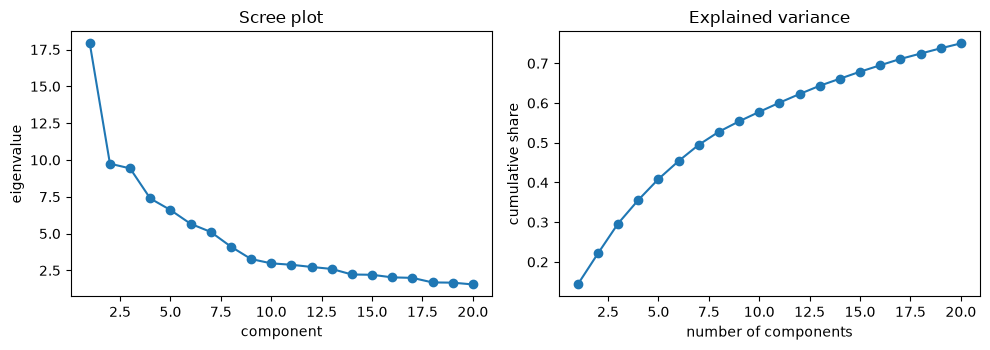

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(range(1, 21), eigval[:20], "o-")
ax[0].set_xlabel("component"); ax[0].set_ylabel("eigenvalue"); ax[0].set_title("Scree plot")
ax[1].plot(range(1, 21), share[:20].cumsum(), "o-")
ax[1].set_xlabel("number of components"); ax[1].set_ylabel("cumulative share"); ax[1].set_title("Explained variance")
plt.tight_layout()
plt.savefig(RESULTS / "scree_plot.png", dpi=150)
plt.show()

In [10]:
kmax = 10
rows = []
for k in range(kmax + 1):
    V = eigval[k:].sum() / N      # average squared residual with k factors
    c = (N + T) / (N * T)
    rows.append((k,
                 np.log(V) + k * c * np.log(N * T / (N + T)),
                 np.log(V) + k * c * np.log(min(N, T)),
                 np.log(V) + k * np.log(min(N, T)) / min(N, T)))
ic = pd.DataFrame(rows, columns=["k", "IC1", "IC2", "IC3"]).set_index("k")
print(ic.round(3).T)
print("selected k:", ic.idxmin().to_dict())

k     0      1      2      3      4      5      6      7      8      9      10
IC1  0.0 -0.096 -0.134 -0.177 -0.207 -0.234 -0.255 -0.275 -0.284 -0.283 -0.279
IC2  0.0 -0.089 -0.119 -0.156 -0.178 -0.198 -0.212 -0.225 -0.227 -0.218 -0.208
IC3  0.0 -0.116 -0.173 -0.236 -0.285 -0.332 -0.373 -0.413 -0.441 -0.460 -0.476
selected k: {'IC1': 8, 'IC2': 8, 'IC3': 10}


## Forecasting

In [11]:
TARGET, H, PMAX = "INDPRO", 1, 6
EVAL_START, EVAL_END = "2000-01-01", "2004-12-31"

y = panel_no_acogno[TARGET].to_numpy()
dates = panel_no_acogno.index

def design(y, p, s_start, s_end):
    # rows s = s_start..s_end: regressors y[s], ..., y[s-p+1]; target y[s+1]
    X = np.column_stack([np.ones(s_end - s_start + 1)] + [y[s_start - j : s_end - j + 1] for j in range(p)])
    return X, y[s_start + 1 : s_end + 2]

def fit_bic(y, p, i):
    # uses only y[0..i] (information available at forecast origin i); common sample for every p
    X, z = design(y, p, PMAX - 1, i - 1)
    b = np.linalg.lstsq(X, z, rcond=None)[0]
    rss = np.sum((z - X @ b) ** 2); n, k = len(z), X.shape[1]
    return n * np.log(rss / n) + k * np.log(n), b

origins = [i for i in range(len(dates) - 1) if EVAL_START <= str(dates[i + 1].date()) <= EVAL_END]
rows = []
for i in origins:
    fits = {p: fit_bic(y, p, i) for p in range(1, PMAX + 1)}
    p_star = min(fits, key=lambda p: fits[p][0])
    b = fits[p_star][1]
    x_t = np.r_[1.0, y[i - np.arange(p_star)]]
    rows.append({"forecast_for": dates[i + 1], "actual": y[i + 1], "ar_forecast": x_t @ b,
                 "mean_forecast": y[: i + 1].mean(), "p": p_star})

fc = pd.DataFrame(rows).set_index("forecast_for")
fc["ar_error"] = fc["actual"] - fc["ar_forecast"]
fc["mean_error"] = fc["actual"] - fc["mean_forecast"]
fc.round(6).to_csv(RESULTS / "ar_baseline_forecasts.csv")

msfe_ar, msfe_mean = (fc["ar_error"] ** 2).mean(), (fc["mean_error"] ** 2).mean()
print("n forecasts:", len(fc), "| first:", fc.index[0].date(), "| last:", fc.index[-1].date())
print("chosen p counts:", fc["p"].value_counts().sort_index().to_dict())
print("MSFE  AR:", f"{msfe_ar:.3e}", " mean:", f"{msfe_mean:.3e}")
print("RMSE  AR:", round(np.sqrt(msfe_ar), 5), " mean:", round(np.sqrt(msfe_mean), 5))
print("MSFE AR / MSFE mean:", round(msfe_ar / msfe_mean, 3))

n forecasts: 60 | first: 2000-01-01 | last: 2004-12-01
chosen p counts: {1: 16, 2: 13, 3: 31}
MSFE  AR: 2.093e-05  mean: 2.508e-05
RMSE  AR: 0.00458  mean: 0.00501
MSFE AR / MSFE mean: 0.835


In [12]:
Xall = panel_no_acogno.to_numpy().copy()
y = panel_no_acogno[TARGET].to_numpy().copy()

def pca_window(X_hist):
    mu, sd = X_hist.mean(axis=0), X_hist.std(axis=0, ddof=0)     # standardise with data up to the origin only
    Z = (X_hist - mu) / sd
    eigval, eigvec = np.linalg.eigh(np.cov(Z, rowvar=False, ddof=0))
    order = np.argsort(eigval)[::-1]
    return Z, eigval[order], eigvec[:, order]

def select_r_ic2(eigval, T, N, kmax=8):
    c = (N + T) / (N * T)
    ic = [np.log(eigval[k:].sum() / N) + k * c * np.log(min(N, T)) for k in range(kmax + 1)]
    return int(np.argmin(ic))

def design_di(y, F, p, s_start, s_end):
    cols = [np.ones(s_end - s_start + 1)] + [F[s_start : s_end + 1, j] for j in range(F.shape[1])] \
           + [y[s_start - j : s_end - j + 1] for j in range(p)]
    return np.column_stack(cols), y[s_start + 1 : s_end + 2]

def di_forecast(Xall, y, r, i):
    Z, eigval, eigvec = pca_window(Xall[: i + 1])                  # only information up to origin i
    if r == "ic2":
        r = select_r_ic2(eigval, *Z.shape)
    F = Z @ eigvec[:, :r]
    best = None
    for p in range(1, PMAX + 1):                                   # p chosen by BIC on a common sample
        X, z = design_di(y, F, p, PMAX - 1, i - 1)
        b = np.linalg.lstsq(X, z, rcond=None)[0]
        rss = np.sum((z - X @ b) ** 2); n, k = len(z), X.shape[1]
        bic = n * np.log(rss / n) + k * np.log(n)
        if best is None or bic < best[0]:
            best = (bic, b, p)
    _, b, p = best
    return np.r_[1.0, F[i], y[i - np.arange(p)]] @ b, r, p

ar_err = fc["ar_error"].to_numpy()
msfe_ar = (ar_err ** 2).mean()

summary, di_fc = [], pd.DataFrame(index=fc.index)
for r in (4, 1, 6, "ic2"):
    res = [di_forecast(Xall, y, r, i) for i in origins]
    pred = np.array([f[0] for f in res])
    err = y[[i + 1 for i in origins]] - pred
    di_fc[f"di_r{r}"] = pred
    rs = [f[1] for f in res]
    summary.append({"model": f"DI r={r}", "r_used": f"{min(rs)}-{max(rs)}" if min(rs) != max(rs) else str(rs[0]),
                    "MSFE": (err ** 2).mean(), "rel_MSFE_vs_AR": (err ** 2).mean() / msfe_ar})

summary = pd.DataFrame(summary).set_index("model")
print(summary.round(4))
print("AR MSFE:", f"{msfe_ar:.3e}")
summary.to_csv(RESULTS / "di_vs_ar_summary.csv")
di_fc.round(6).to_csv(RESULTS / "di_forecasts.csv")

         r_used  MSFE  rel_MSFE_vs_AR
model                                
DI r=4        4   0.0          1.1245
DI r=1        1   0.0          0.9910
DI r=6        6   0.0          1.1099
DI r=ic2    4-8   0.0          1.0254
AR MSFE: 2.093e-05


           RMSE  RMSE_ratio_vs_AR  MSFE_ratio_vs_AR    CW_t  CW_p_onesided
model                                                                     
di_r4    0.0049            1.0604            1.1245  1.2861         0.0992
di_r1    0.0046            0.9955            0.9910  1.4820         0.0692
di_r6    0.0048            1.0535            1.1099  1.7634         0.0389
di_ric2  0.0046            1.0126            1.0254  2.0330         0.0210
AR RMSE: 0.00458
2000-2001 n = 24 | MSFE ratio r=4: 1.376 | r=1: 1.067
2002-2004 n = 36 | MSFE ratio r=4: 0.955 | r=1: 0.939


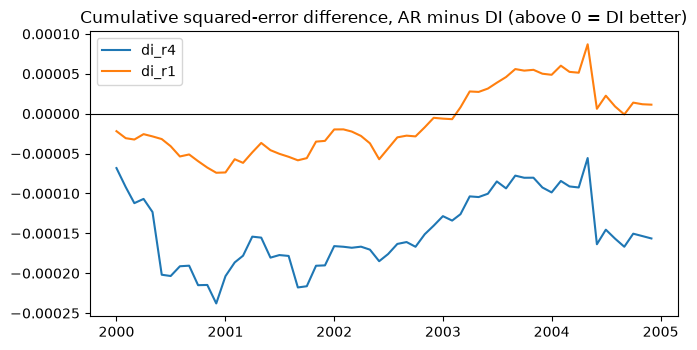

In [13]:
from math import erf, sqrt
import matplotlib.pyplot as plt

def norm_cdf(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

def clark_west(actual, f_restricted, f_unrestricted):
    # H0: restricted (AR) is as good as the nesting model; H1: the larger (DI) model is better (one-sided)
    e1, e2 = actual - f_restricted, actual - f_unrestricted
    adj = e1 ** 2 - (e2 ** 2 - (f_restricted - f_unrestricted) ** 2)
    t = adj.mean() / (adj.std(ddof=1) / np.sqrt(len(adj)))
    return t, 1 - norm_cdf(t)

a = fc["actual"].to_numpy()
f_ar = fc["ar_forecast"].to_numpy()
e_ar = a - f_ar

rows = []
for col in di_fc.columns:
    f_di = di_fc[col].to_numpy()
    e_di = a - f_di
    t, pv = clark_west(a, f_ar, f_di)
    rows.append({"model": col,
                 "RMSE": np.sqrt((e_di ** 2).mean()),
                 "RMSE_ratio_vs_AR": np.sqrt((e_di ** 2).mean()) / np.sqrt((e_ar ** 2).mean()),
                 "MSFE_ratio_vs_AR": (e_di ** 2).mean() / (e_ar ** 2).mean(),
                 "CW_t": t, "CW_p_onesided": pv})
eval_tab = pd.DataFrame(rows).set_index("model")
eval_tab.to_csv(RESULTS / "evaluation_table.csv")
print(eval_tab.round(4).to_string())
print("AR RMSE:", round(np.sqrt((e_ar ** 2).mean()), 5))

# Sub-periods (descriptive only)
for name, (s, e) in {"2000-2001": ("2000-01-01", "2001-12-31"), "2002-2004": ("2002-01-01", "2004-12-31")}.items():
    m = (fc.index >= s) & (fc.index <= e)
    r4 = ((a[m] - di_fc["di_r4"].to_numpy()[m]) ** 2).mean() / (e_ar[m] ** 2).mean()
    r1 = ((a[m] - di_fc["di_r1"].to_numpy()[m]) ** 2).mean() / (e_ar[m] ** 2).mean()
    print(name, "n =", int(m.sum()), "| MSFE ratio r=4:", round(r4, 3), "| r=1:", round(r1, 3))

# Cumulative squared-error difference: rising line = DI better than AR
fig, ax = plt.subplots(figsize=(7, 3.6))
for col in ["di_r4", "di_r1"]:
    ax.plot(fc.index, np.cumsum(e_ar ** 2 - (a - di_fc[col].to_numpy()) ** 2), label=col)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Cumulative squared-error difference, AR minus DI (above 0 = DI better)")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "cum_sse_difference.png", dpi=150)
plt.show()

## Evaluation

## Results

In [7]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 17.4 MB/s  0:00:00 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 15.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 13.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
